# Ridge regression: viewer ratings

Predict **TMDB viewer rating (`vote_average`, 0–10)**.

Run All from this folder using **ds6001**. CSVs are read-only inputs; model choices and comparison versions are preserved.

## 1. Setup and controls
Edit the next cell, save, then Run All. Extra comparisons, coefficients, and full diagnostics are optional. Keep dates/folds consistent across models.

In [1]:
# Edit model/search settings here; shared goals live in project_policy.py.
from pathlib import Path
import sys
sys.path.insert(0, str(Path('..').resolve()))
from project_policy import (CUTOFF_DATE, N_VALIDATION_SPLITS, RATING_SELECTION_METRIC,
    RATING_METRIC_GOALS, RATING_STRETCH_GOALS, SUCCESS_SELECTION_METRIC,
    SUCCESS_MIN_VALIDATION_PRECISION, SUCCESS_THRESHOLDS, BASE_THRESHOLD,
    OVERLAP_MAE_TOLERANCE, OVERLAP_HIT_F1_TOLERANCE, OVERLAP_MACRO_F1_TOLERANCE)
DATA_FILE = '../../data/model_data_rating.csv'

MODEL_SETTINGS = {'alpha': 10.0}
PARAM_GRID = {'preprocessor__numeric__polynomial__degree': [1, 2],
 'preprocessor__numeric__imputer__add_indicator': [False, True],
 'regression__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]}
TUNING_METRIC = RATING_SELECTION_METRIC
FEATURE_GROUPS_TO_COMPARE = ['Movie characteristics', '+ Director history', '+ Actor history', 'All features']
RATING_GOALS = dict(RATING_METRIC_GOALS)
STRETCH_GOALS = dict(RATING_STRETCH_GOALS)
OVERLAP_TRIMS = ['Drop genre count', 'Lean history', 'Lean history + director count']
SHOW_EXTRA_COMPARISONS = False
SHOW_COEFFICIENTS = False
SHOW_DIAGNOSTIC_DETAILS = False

In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path('..').resolve()))
from model_workflow import (load_data, train_models, show_validation, show_results,
                            show_diagnostics_summary, save_report)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import Ridge

data = load_data(DATA_FILE, 'rating', CUTOFF_DATE, N_VALIDATION_SPLITS)

13,276 movies | 9,405 training / 3,871 later test | 40 available predictors


## 2. Model
The preprocessing and estimator are defined here. Missing-value filling, scaling, encoding and any polynomial/PCA transformations are fitted anew inside each training fold.

In [3]:
def make_model(columns):
    """Fresh preprocessing and regression for each feature set and split."""
    numeric = [column for column in data["NUMERIC_FEATURES"] if column in columns]
    categorical = [column for column in data["CATEGORICAL_FEATURES"] if column in columns]
    binary = [column for column in data["BINARY_FEATURES"] if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=1, include_bias=False)),
            ("expanded_scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("regression", Ridge(**MODEL_SETTINGS)),
    ])

## 3. Validation and tuning
One call runs settings, feature-group selection, then the bounded overlap review on the same expanding **training-only** folds. The later test period never selects candidates. These reused validation scores are exploratory selection estimates.

Shared implementation: [model_workflow.py](../model_workflow.py).

In [4]:
run = train_models(make_model, data, globals(), joint_search=True)
show_validation(run, details=SHOW_EXTRA_COMPARISONS)

Selected using three earlier-to-later folds inside training.


,MAE,RMSE,R2,Predictors
0,0.5077,0.6562,0.336,33


Parameters: {'preprocessor__numeric__imputer__add_indicator': True, 'preprocessor__numeric__polynomial__degree': 2, 'regression__alpha': 10.0}
Trim selected using chronological training validation only.


## 4. Final results
Compare MAE/RMSE/R² with the training-mean baseline; lower errors are better. Training versus later-test results show generalization.

One main plot is shown here. All-model charts and residual/ROC/precision–recall plots are in [model visualizations](../../Data_visualization/model_visualizations.ipynb).

,Model,Split,MAE,RMSE,R2
0,Dummy baseline,Test,0.6123,0.7746,-0.0734
1,Selected,Training,0.4847,0.6231,0.3964
2,Selected,Test,0.4985,0.6395,0.2684


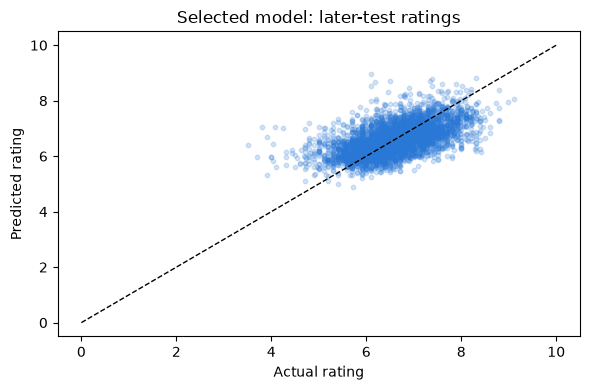

In [5]:
results = show_results(run, extra=SHOW_EXTRA_COMPARISONS, coefficients=SHOW_COEFFICIENTS)

## 5. Diagnostics
Review the short safeguards and before/after VIF table. Remaining correlations require cautious interpretation, not automatic deletion. Retrospective histories, missing finances and repeated test inspection limit generalization.

The [diagnostics guide](../DIAGNOSTICS.md) explains findings and next experiments. Full tables remain in `diagnostic_results`; the top switch displays them. The final line refreshes the generated comparison report without changing datasets.

Next experiments: compare further history trims or missing-budget indicators inside chronological training validation; avoid choosing from the already-inspected test scores.

In [6]:
diagnostic_results = show_diagnostics_summary(run)
report_path = save_report(run, Path('ridge_model.ipynb'))
print("Saved comparison report:", report_path)

,Check,Result
0,Programmed data/chronology safeguards,PASS; historical availability still unverified
1,Remaining overlap,4 inputs have VIF ≥10; coefficients need cauti...
2,Missing training inputs,log_budget: 3222 missing
3,Numerical fitting,"{'Estimator': 'Ridge', 'Nonzero coefficients':..."
4,Generalization limits,"Later movies, missing finances and retrospecti..."


Overlap review: fewer redundant inputs; high VIF alone does not invalidate predictions.


,Stage,Predictors,Transformed inputs,VIF >=10,Maximum VIF,Removed
0,Before overlap trim,38,130.0,52.0,682.745,None
1,After overlap review,33,86.0,4.0,19.731,"n_genres, imdb_director_count, dir_years_active_log1p, dir_prior_known_films_log1p, dir_prior_rated_films_log1p"


Next: compare further experiments only inside chronological training validation. Full technical tables are in diagnostic_results; set SHOW_DIAGNOSTIC_DETAILS=True to display them.


Saved comparison report: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/rating/ridge_model.json
